In [18]:
MODEL_NAME_MAPPING = {
    'ms-marco-MiniLM-L12-v2': "MS-MARCO-MiniLM",
    'ms-marco-MiniLM-L-12-v2': "MS-MARCO-MiniLM",
    'BiomedNLP-BiomedBERT-base-uncased-abstract-fulltext': 'BioMedBERT',
    'gemini-2.5-pro-preview-03-25': "Gemini 2.5",
    'gpt-4.1': 'GPT 4.1',
    'bert-large-uncased': 'BERT',
    'MedCPT-Cross-Encoder': 'MedCPT',
    'specter2_base': 'Specter2',
    'specter': 'Specter',
    'tfidf': 'TF-IDF',
    'bge-reranker-large': 'BGE',
    'Meta-Llama-3.1-Instruct': 'Llama 3.1',
    'Mixtral--Instruct-v0.1': 'Mixtral',
    'multilingual-e5-large-instruct': 'Multilingual E5',
    'bm25-lucene': 'BM25',
    'reranker-ModernBERT-large-gooaq-bce': 'ModernBERT',
    'Qwen3-Reranker-4B': 'Qwen 3 [4B]',
    'Qwen3-Reranker-0.6B': 'Qwen 3 [0.6B]',
    'Qwen3-Reranker-8B': 'Qwen 3 [8B]',
    'gpt-5.2': 'GPT 5.2',
    'Llama-4-Scout-17B-16E-Instruct': 'Llama 4-Scout'
}

MODEL_SIZE = {
    "MS-MARCO-MiniLM": 0.334,
    'BioMedBERT': 0.11,
    'BERT': 0.3,
    'MedCPT': 0.33,
    'BGE': 0.6,
    'ModernBERT': 0.4,
    'Qwen3 4B': 4,
    'Qwen3 0.6B': 0.6,
    'Qwen3 8B': 8
}

QUERY_TEMPLATE_NAMES = {
    0: 'JSON',
    # 1: 'col:value lines',
    2: 'values only',
    3: 'tab-delimited',
    4: 'NL',
    5: 'col is value;',
    # 6: 'value list',
    # 7: 'molecularProfile only'
}

In [19]:
from utils import read_jsonl
import subprocess
import glob

PARTITION = '*'
VERSION = '2026.03.03'

EXCLUDE = {'NeuML__biomedbert-base-reranker', 'nicolauduran45__climate-science-reranker'}

files = [f for f in subprocess.check_output(f"find ../results/evidence_retrieval/cross -regex '.*-{VERSION}/.*.{PARTITION}.retrieval_accuracy.jsonl.gz'", shell=True).decode().split('\n') if f.strip()]
# files += [f for f in subprocess.check_output(f"find ../results/claim_verification -regex '.*-{VERSION}/.*.{PARTITION}.retrieval_accuracy.jsonl.gz'", shell=True).decode().split('\n') if f.strip()]
bm25_files = list(glob.glob(f'../results/evidence_retrieval/bi/evaluations/bm25-lucene/*-{VERSION}/qt*/*.{PARTITION}.retrieval_accuracy.jsonl.gz'))
print(f'found {len(bm25_files)} bm25 files')
assert len(bm25_files) > 0
files = files + bm25_files

head_files= list(glob.glob(f'../results/evidence_retrieval/bi/evaluations/head*/*-{VERSION}/qt*/data.{PARTITION}.retrieval_accuracy.jsonl.gz'))
print(f'found {len(head_files)} head files')
assert len(head_files) > 0
files = files + head_files

print(f'found {len(files)} files')
files = [f for f in files if not set(f.split('/')) & EXCLUDE]
df = read_jsonl(*files, add_filepath_metadata=True, add_filename=True)
df = df[~df['filepath.query_template'].isin({'7', '1', '6'})]

for col in ["filepath.train_dataset", "filepath.config"]:
    if col not in df.columns:
        df[col] =''
df["filepath.train_dataset"] = df["filepath.train_dataset"].fillna("")

df['fine-tuned'] = df["filepath.train_dataset"].apply(lambda ftd: 'yes' if ftd else 'no')

df['model'] = df['filepath.model_dir'].apply(lambda model_dir: model_dir.split('__')[-1])
df['model'] = df.model.apply(lambda model: MODEL_NAME_MAPPING.get(model, model))
document_claims = []

max_k = df["document.total_chunks"].max()
print('max_k:', max_k)

df = df[(~df['filepath.model_dir'].str.contains('mxbai')) & (~df['filepath.model_dir'].str.contains('tfidf')) ]
df['query_template'] = df['filepath.query_template'].astype(int).apply(lambda t: QUERY_TEMPLATE_NAMES.get(t, t))


for _, row in df.drop_duplicates(['filename']).iterrows():
    print({c:v for c, v in row.items() if c.startswith('file')})
print(df.columns)
df.head()

found 17 bm25 files
found 6 head files
found 259 files
max_k: 138
{'filename': '../results/evidence_retrieval/cross/fine-tuning/anchors/config-10/civicfact-2026.03.03/qt0/ncbi__MedCPT-Cross-Encoder/evaluations/civicfactpairs-2026.03.03/qt0/data.dev.retrieval_accuracy.jsonl.gz', 'filepath.task': 'evidence_retrieval', 'filepath.encoding': 'cross', 'filepath.train_data_format': 'anchors', 'filepath.config': '10', 'filepath.train_dataset': 'civicfact', 'filepath.train_data_version': '2026.03.03', 'filepath.train_query_template': '0', 'filepath.model_dir': 'ncbi__MedCPT-Cross-Encoder', 'filepath.eval_dataset': 'civicfactpairs', 'filepath.ret_model': None, 'filepath.ret_length': None, 'filepath.ret_query_template': None, 'filepath.subsample_fraction': None, 'filepath.subsample_filter': None, 'filepath.subsample_seed': None, 'filepath.data_version': '2026.03.03', 'filepath.query_template': '0', 'filepath.partition': 'dev'}
{'filename': '../results/evidence_retrieval/cross/fine-tuning/anchors/

,accuracy_level,all_chunks,ap@k,civic.id,claim.flat,document.content_source,document.doi,document.length,document.license,document.pmcid,...,filepath.subsample_fraction,filepath.subsample_filter,filepath.subsample_seed,filepath.data_version,filepath.query_template,filepath.partition,revised_claim.flat,fine-tuned,model,query_template
0,claim,"[{'chunk.id': '23761041:0-1000', 'chunk.start'...",NaN,[113],"{\n ""disease"": ""Acute Myeloid Leukemia"",\n ""...",pubmed,NaN,1843,,NaN,...,None,None,None,2026.03.03,0,dev,NaN,yes,MedCPT,JSON
1,claim,"[{'chunk.id': '21067377:0-1000', 'chunk.start'...","[{'ap': 0.0, 'k': 1, 'positive': 0.0, 'recall'...",[113],"{\n ""disease"": ""Acute Myeloid Leukemia"",\n ""...",pmc_author_fulltext,10.1056/NEJMoa1005143,28652,,PMC3201818,...,None,None,None,2026.03.03,0,dev,NaN,yes,MedCPT,JSON
2,claim,"[{'chunk.id': '25759020:0-1000', 'chunk.start'...",NaN,[176],"{\n ""disease"": ""Acute Myeloid Leukemia"",\n ""...",pmc_author_fulltext,NaN,41061,,NaN,...,None,None,None,2026.03.03,0,dev,NaN,yes,MedCPT,JSON
3,claim,"[{'chunk.id': '23737213:0-1000', 'chunk.start'...",NaN,[1514],"{\n ""disease"": ""Acute Myeloid Leukemia"",\n ""...",pmc_author_fulltext,NaN,28389,,NaN,...,None,None,None,2026.03.03,0,dev,NaN,yes,MedCPT,JSON
4,claim,"[{'chunk.id': '21067377:0-1000', 'chunk.start'...","[{'ap': 0.0, 'k': 1, 'positive': 0.0, 'recall'...",[113],"{\n ""disease"": ""Acute Myeloid Leukemia"",\n ""...",pmc_author_fulltext,10.1056/NEJMoa1005143,28652,,PMC3201818,...,None,None,None,2026.03.03,0,dev,NaN,yes,MedCPT,JSON


In [20]:
import pandas as pd

df = df[df['positive_chunks'].str.len() > 0]
df = df[~df.model.isin(['BERT', 'Multilingual E5'])]

hard_df = read_jsonl('../data/civicfact-2026.03.03/filters.hard.jsonl.gz')
hard_df['subset'] = '[hard]'

# df = df[df['document.content_source'] != 'pubmed']
all_df = df.copy()

both_df = pd.concat([all_df, all_df.merge(hard_df)])
both_df['subset'] = both_df['filepath.partition'] + both_df['subset'].fillna('')


# df = df[df.abstract_only == False]


In [21]:
from evidence_retrieval.summarize_ranking_accuracy import _mapk_by_doc_length, _map_by_k
from utils.fig import generate_hue_map
import seaborn as sns
import pandas as pd

sns.set_style('whitegrid')


map_df = df.explode('ap@k')
map_df = map_df[~map_df['ap@k'].isna()]  # ignore things without a ground truth
map_df['ap'] = map_df['ap@k'].str['ap']
map_df['k'] = map_df['ap@k'].str['k']
map_df['recall'] = map_df['ap@k'].str['recall']

max_k = map_df['k'].max()
# for all documents where k < max_k, set k-max_k to the last ap
ID_COLUMNS = ['claim.flat', 'document.pmid', 'filename']
if 'id' in map_df.columns:
    ID_COLUMNS += ['id']

last_ap_df = map_df.sort_values(['k']).drop_duplicates(ID_COLUMNS, keep='last')
last_ap = []
for k in range(map_df['k'].min(), max_k + 1):
    temp_df = last_ap_df.copy()
    temp_df['k'] = k
    last_ap.append(temp_df)
last_ap_df = pd.concat(last_ap)

map_df = pd.concat([map_df, last_ap_df]).drop_duplicates(ID_COLUMNS + ['k'], keep='first')
doc_map_df = map_df.groupby([c for c in map_df.columns if c.startswith('document.') or c.startswith('filepath')] + ['k', 'filename', 'fine-tuned', 'model', 'query_template'] , dropna=False).agg({'ap': 'mean'}).reset_index()

map_df.head()

,accuracy_level,all_chunks,ap@k,civic.id,claim.flat,document.content_source,document.doi,document.length,document.license,document.pmcid,...,filepath.data_version,filepath.query_template,filepath.partition,revised_claim.flat,fine-tuned,model,query_template,ap,k,recall
1,claim,"[{'chunk.id': '21067377:0-1000', 'chunk.start'...","{'ap': 0.0, 'k': 1, 'positive': 0.0, 'recall':...",[113],"{\n ""disease"": ""Acute Myeloid Leukemia"",\n ""...",pmc_author_fulltext,10.1056/NEJMoa1005143,28652,,PMC3201818,...,2026.03.03,0,dev,NaN,yes,MedCPT,JSON,0.000000,1,0.000000
1,claim,"[{'chunk.id': '21067377:0-1000', 'chunk.start'...","{'ap': 0.5, 'k': 2, 'positive': 1.0, 'recall':...",[113],"{\n ""disease"": ""Acute Myeloid Leukemia"",\n ""...",pmc_author_fulltext,10.1056/NEJMoa1005143,28652,,PMC3201818,...,2026.03.03,0,dev,NaN,yes,MedCPT,JSON,0.500000,2,0.166667
1,claim,"[{'chunk.id': '21067377:0-1000', 'chunk.start'...","{'ap': 0.583333333333333, 'k': 3, 'positive': ...",[113],"{\n ""disease"": ""Acute Myeloid Leukemia"",\n ""...",pmc_author_fulltext,10.1056/NEJMoa1005143,28652,,PMC3201818,...,2026.03.03,0,dev,NaN,yes,MedCPT,JSON,0.583333,3,0.333333
1,claim,"[{'chunk.id': '21067377:0-1000', 'chunk.start'...","{'ap': 0.583333333333333, 'k': 4, 'positive': ...",[113],"{\n ""disease"": ""Acute Myeloid Leukemia"",\n ""...",pmc_author_fulltext,10.1056/NEJMoa1005143,28652,,PMC3201818,...,2026.03.03,0,dev,NaN,yes,MedCPT,JSON,0.583333,4,0.333333
1,claim,"[{'chunk.id': '21067377:0-1000', 'chunk.start'...","{'ap': 0.583333333333333, 'k': 5, 'positive': ...",[113],"{\n ""disease"": ""Acute Myeloid Leukemia"",\n ""...",pmc_author_fulltext,10.1056/NEJMoa1005143,28652,,PMC3201818,...,2026.03.03,0,dev,NaN,yes,MedCPT,JSON,0.583333,5,0.333333


In [22]:
# import pandas as pd

# result= []

# for i in range(1, map_df['document.total_chunks'].max() + 1):
#     temp_df =  map_df[(map_df.k == 5) & (map_df['document.total_chunks'] >= i)].copy()
#     temp_df['min_document_chunks'] = i
#     result.append(temp_df)

# mapk_by_doc_length_df = pd.concat(result)


In [23]:
# pairs_df = read_jsonl('../data/civicfact-2025.03.25/chunk_retrieval_reference.jsonl.gz')

# pairs_df = (
#     pairs_df.groupby(["id", "claim.flat", "document.pmid"])
#     .agg({"chunk.id": "nunique"})
#     .reset_index()
#     .rename(columns={"chunk.id": "num_chunks"})
# )
# pairs_df["accuracy_level"] = "instance"

document.content_source
pmc                    58506
pmc_author_fulltext    21723
pubmed                  5499
Name: count, dtype: int64
Index(['claim.flat', 'document.pmid', 'filename', 'subset', 'accuracy_level',
       'all_chunks', 'ap@k', 'civic.id', 'document.content_source',
       'document.doi', 'document.length', 'document.license', 'document.pmcid',
       'document.title', 'document.total_chunks', 'positive_chunks',
       'revised_claims', 'filepath.task', 'filepath.encoding',
       'filepath.train_data_format', 'filepath.config',
       'filepath.train_dataset', 'filepath.train_data_version',
       'filepath.train_query_template', 'filepath.model_dir',
       'filepath.eval_dataset', 'filepath.ret_model', 'filepath.ret_length',
       'filepath.ret_query_template', 'filepath.subsample_fraction',
       'filepath.subsample_filter', 'filepath.subsample_seed',
       'filepath.data_version', 'filepath.query_template',
       'filepath.partition', 'revised_claim.flat', 'fin

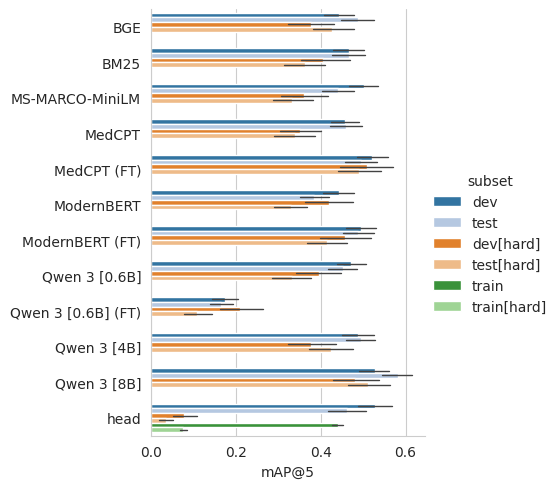

In [24]:
# mAP@5
from utils.fig import add_bar_labels, ci_95

k = 5
fig_df = both_df[ID_COLUMNS + ['subset']].merge(map_df)
fig_df = fig_df[(fig_df.k == k) ].copy()
fig_df.loc[fig_df['fine-tuned'] == 'yes', 'model'] += ' [FT' + fig_df['filepath.config'] + ']'

fig_df = fig_df[~fig_df.model.isin({'Qwen 3 reranker [0.6B] [FT10]', 'MedCPT [FT12]', 'BioMedBERT'})]
print(fig_df['document.content_source'].value_counts())
fig_df['mAP'] = fig_df['ap']

# pick the best query template on the hard dataset for each model
query_template_df = fig_df[fig_df.subset == 'dev[hard]'].groupby(['model', 'query_template'], dropna=False).agg({'mAP': 'mean'}).reset_index()
query_template_df = query_template_df.sort_values(['mAP']).drop_duplicates(['model'], keep='last')
fig_df = fig_df.merge(query_template_df[['model', 'query_template']].drop_duplicates())

print(fig_df.columns)
print(ID_COLUMNS)

# fig_df = pd.melt(fig_df, id_vars=[ 'model', 'subset', 'filepath.query_template'] + ID_COLUMNS, value_vars=['mAP', 'recall'], var_name='metric')


bar_kws = dict(err_kws={'linewidth': 1}, estimator='mean', errorbar=('ci', 95), n_boot=1000)

fig_df = fig_df[~fig_df.model.isin({'MS-MARCO-MiniLM [FT10]', 'BioMedBERT [FT10]', 'head-oracle', 'Specter', 'Specter2'})]
fig_df['model'] = fig_df['model'].str.replace('[FT10]', '(FT)', regex=False)
print(fig_df.model.unique().tolist())

part_c_df = fig_df.sort_values(['model'])
fig = sns.catplot(part_c_df, y='model', x='mAP', kind='bar', palette='tab20', hue='subset',  **bar_kws)
fig.set(xlabel=f'mAP@{k}', ylabel='')
# add_bar_labels(fig, fmt=lambda x: round(x, 2), padding=5)

In [25]:
df = pd.pivot_table(part_c_df.groupby(['model', 'subset']).agg({'mAP': 'mean'}).reset_index(), values='mAP', columns='subset', index='model').reset_index().sort_values(['dev', 'dev[hard]'], ascending=False).merge(query_template_df[['model', 'query_template']], how='left')
# df['filepath.query_template'] = df['filepath.query_template'].apply(lambda qt: QUERY_TEMPLATE_NAMES.get(str(qt), qt))
print(df.to_csv(index=False))

model,dev,dev[hard],test,test[hard],train,train[hard],query_template
head,0.528962703962704,0.0790123456790123,0.46225799663299666,0.03567839195979899,0.4400165647298675,0.07618167033889411,JSON
Qwen 3 [8B],0.5269522144522143,0.4820387517146775,0.5811132154882154,0.5116903964265772,,,col is value;
MedCPT (FT),0.5214516964516964,0.5091220850480108,0.49468294051627376,0.49003350083752084,,,
MS-MARCO-MiniLM,0.5012432012432012,0.36174554183813434,0.4405162738496071,0.3329006141820212,,,NL
ModernBERT (FT),0.49603405853405846,0.45790466392318235,0.48881874298540956,0.41423785594639856,,,
Qwen 3 [4B],0.48873348873348865,0.37832647462277086,0.4948583052749718,0.4249441652707983,,,col is value;
Qwen 3 [0.6B],0.4722157472157471,0.39624485596707815,0.45167648709315367,0.33362646566164145,,,col is value;
BM25,0.467100492100492,0.405366941015089,0.46662457912457905,0.3630234505862646,,,NL
MedCPT,0.45801605801605794,0.35102880658436203,0.45869107744107734,0.33951702959240637,,,NL
BGE,0.4427285677285

## What is the Impact of the Query Template Used?

['claim.flat', 'document.pmid', 'filename']
<ArrowStringArray>
[         'MedCPT', 'MS-MARCO-MiniLM',      'BioMedBERT',   'Qwen 3 [0.6B]',
      'ModernBERT',             'BGE',        'Specter2',         'Specter',
     'Qwen 3 [4B]',     'Qwen 3 [8B]',            'BM25',            'head',
     'head-oracle']
Length: 13, dtype: str
<ArrowStringArray>
[            'BGE', 'MS-MARCO-MiniLM',          'MedCPT',   'Qwen 3 [0.6B]',
      'ModernBERT',     'Qwen 3 [4B]',     'Qwen 3 [8B]',            'BM25']
Length: 8, dtype: str


,claim.flat,document.pmid,subset,model,filepath.model_dir,mAP spread,filepath.query_template
0,"{\n ""disease"": ""Acute Lymphoblastic Leukemia""...",25807284,train,BM25,bm25-lucene,NaN,1
1,"{\n ""disease"": ""Acute Lymphoblastic Leukemia""...",25807284,train,BM25,bm25-lucene,NaN,1
2,"{\n ""disease"": ""Acute Myeloid Leukemia With I...",22180162,train,BM25,bm25-lucene,NaN,1
3,"{\n ""disease"": ""Acute Myeloid Leukemia With T...",28112737,train,BM25,bm25-lucene,NaN,1
4,"{\n ""disease"": ""Acute Myeloid Leukemia"",\n ""...",23029227,train,BM25,bm25-lucene,NaN,1


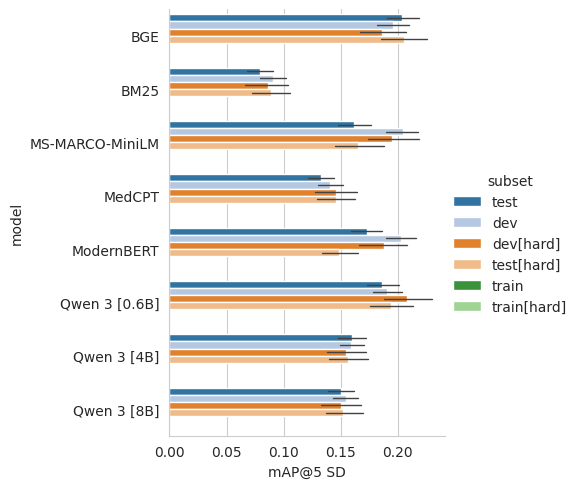

In [26]:
## can we calculate variation per exampe across query templates @ k = 5?

print(ID_COLUMNS)
k = 5
fig_df = both_df[ID_COLUMNS + ['subset']].merge(map_df[map_df.k == k])
print(fig_df.model.unique())
qt_df = fig_df[(fig_df['fine-tuned'] == 'no') & (~fig_df.model.isin({'head', 'BioMedBERT', 'Specter', 'Specter2'}))].copy()
keep_df = qt_df.groupby(['model']).agg({'filepath.query_template': 'nunique'}).reset_index()
keep_df = keep_df[keep_df['filepath.query_template'] == 5]
qt_df = qt_df.merge(keep_df[['model']].drop_duplicates())
qt_df['mAP'] = qt_df['ap']
print(qt_df.model.unique())

qt_df = qt_df.groupby(['claim.flat', 'document.pmid', 'subset', 'model', 'filepath.model_dir'], dropna=False).agg({'mAP': 'std', 'filepath.query_template': 'nunique'}).reset_index().rename(columns={'mAP': 'mAP spread'})

bar_kws = dict(err_kws={'linewidth': 1}, estimator='mean', errorbar=('ci', 95), n_boot=1000)
part_d_df = qt_df.sort_values(['model'])
fig = sns.catplot(part_d_df, x='mAP spread', y='model',  kind='bar',  palette='tab20', hue='subset', **bar_kws)
fig.set(xlabel='mAP@5 SD')
qt_df.head()

## Plot the document-based statistics

In [27]:

df = read_jsonl('../data/civicfact-2026.03.03/document_chunks.jsonl.gz')
df['document source'] = df['document.content_source'].str.split('_').str[0]

# if we have both pubmed and pmc version of article, drop the pubmed one (doesn't appear to be an issue)
source_df = df[['document.pmid', 'document.content_source']].drop_duplicates()
source_df['pubmed'] = source_df['document.content_source'] == 'pubmed'
source_df = source_df.sort_values(['pubmed']).drop_duplicates(['document.pmid'], keep='first')
df = df.merge(source_df)
df['chunk.actual_size'] = df['chunk.end'] - df['chunk.start']

doc_df = df.drop_duplicates(['document.pmid', 'chunk.id']).groupby(['document.pmid', 'document.content_source', 'document source', 'partition'], dropna=False).agg({'chunk.id': 'nunique', 'chunk.actual_size': 'sum', 'chunk.overlap': 'first', 'document.total_chunks': 'first'}).reset_index()

doc_df['document_length'] = doc_df['chunk.actual_size'] - (doc_df['document.total_chunks'] - 1) * doc_df['chunk.overlap']


Index(['chunk.end', 'chunk.id', 'chunk.overlap', 'chunk.section', 'chunk.size',
       'chunk.start', 'claim.flat', 'document.content_source', 'document.pmid',
       'document.total_chunks', 'evidence.end', 'evidence.generated',
       'evidence.parts', 'evidence.section', 'evidence.selection_method',
       'evidence.source', 'evidence.start', 'evidence.text', 'evidence.type',
       'gold_label_name', 'id', 'overlap'],
      dtype='str')


Text(0.5, 0, 'document length (characters)')

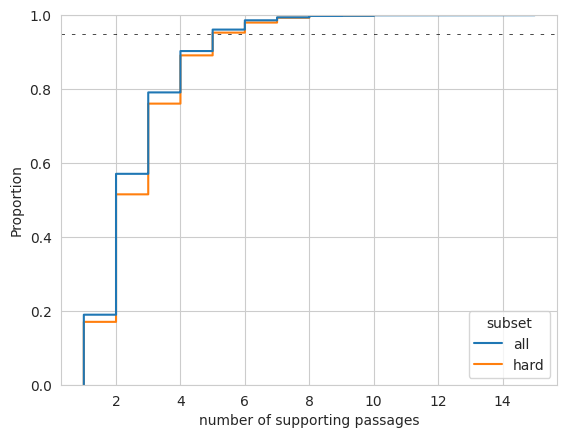

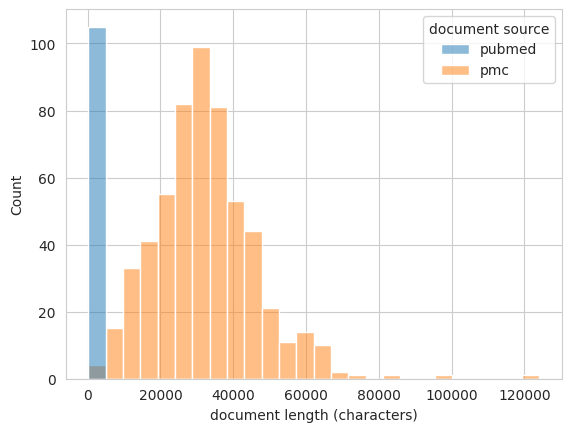

In [28]:
from matplotlib import pyplot as plt

ret_df = read_jsonl('../data/civicfact-2026.03.03/chunk_retrieval_reference.jsonl.gz')
print(ret_df.columns)

ret_df['document source'] = ret_df['document.content_source'].str.split('_').str[0]
doc_df = doc_df.merge(ret_df[['document.pmid']].drop_duplicates())

ret_counts_df = ret_df.groupby(['document.pmid', 'claim.flat']).agg({'chunk.id': 'nunique'}).reset_index()
ret_counts_df['subset'] = 'all'

hard_df = read_jsonl('../data/civicfact-2026.03.03/filters.hard.jsonl.gz')
hard_df = hard_df.drop_duplicates(['claim.flat', 'document.pmid']).merge(ret_counts_df)
hard_df['subset'] = 'hard'

fig_df = pd.concat([ret_counts_df, hard_df])

part_b_df = fig_df
fig = sns.ecdfplot(fig_df, x='chunk.id', hue='subset')
fig.axhline(0.95, linestyle=(0, (5, 10)), color='black', linewidth=0.5)
fig.set_xlabel('number of supporting passages')

plt.figure()
fig_df = doc_df.merge(ret_df[['document.pmid']].drop_duplicates()).drop_duplicates(['document.pmid'])
part_a_df = fig_df
fig = sns.histplot(fig_df, x='document_length', hue='document source')
fig.set_xlabel('document length (characters)')


## all together in a single figure?

count    7970.000000
mean        2.654203
std         1.392619
min         1.000000
25%         2.000000
50%         2.000000
75%         3.000000
max        15.000000
Name: chunk.id, dtype: float64


ValueError: The palette dictionary is missing keys: {'test', 'train[hard]', 'train', 'test[hard]'}

/projects/creisle_prj/git/civicfact/experiments/.venv/lib/python3.12/site-packages/IPython/core/events.py:100: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  func(*args, **kwargs)
/projects/creisle_prj/git/civicfact/experiments/.venv/lib/python3.12/site-packages/IPython/core/pylabtools.py:170: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.canvas.print_figure(bytes_io, **kw)


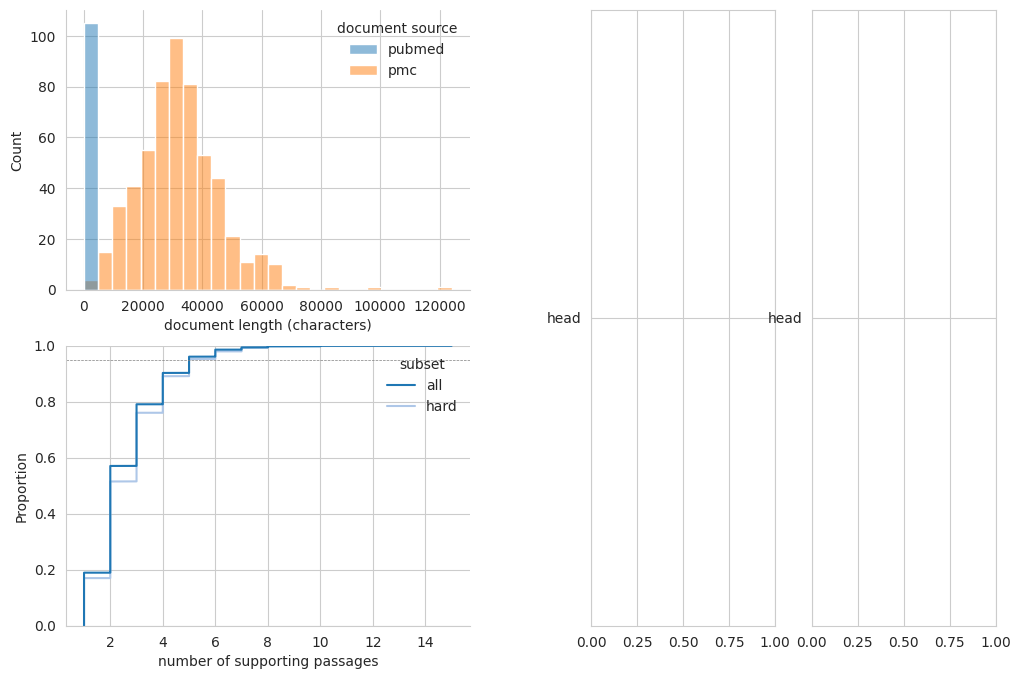

In [29]:
import matplotlib.gridspec as gridspec

def remove_top_right(ax):
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

# Set the base font size globally
plt.rcParams.update({'font.size': 10})

fig = plt.figure(figsize=(12, 8), tight_layout=True)
gs = fig.add_gridspec(nrows=2, ncols=2, hspace=0.2, wspace=0.3)
ax1 = fig.add_subplot(gs[0, 0])
ax2 = fig.add_subplot(gs[1, 0])

sgs = gridspec.GridSpecFromSubplotSpec(1, 2, subplot_spec=gs[:, 1:], wspace=0.2)

ax3 = fig.add_subplot(sgs[:, 0])
ax4 = fig.add_subplot(sgs[:, 1], sharey=ax3)


sns.histplot(part_a_df, x='document_length', hue='document source', ax=ax1)
ax1.set_xlabel('document length (characters)')
sns.move_legend(ax1, loc="upper right", frameon=False)
remove_top_right(ax1)

print(part_b_df['chunk.id'].describe())
hue_map = generate_hue_map(['all', 'hard'], 'tab20')
sns.ecdfplot(part_b_df, x='chunk.id', hue='subset', palette=hue_map, ax=ax2)
ax2.axhline(0.95, linestyle='--', color='grey', linewidth=0.5)
ax2.set_xlabel('number of supporting passages')
sns.move_legend(ax2, loc="upper right", frameon=False)
remove_top_right(ax2)

hue_map = generate_hue_map(['dev', 'dev[hard]'], 'tab20')

model_order = sorted(part_c_df.model.unique().tolist())
start_models = ['head', 'GPT 5.2', 'Llama 4-Scout']
model_order =  start_models + [m for m in model_order if m not in start_models]
part_c_df['model_index'] = part_c_df.model.apply(lambda m: model_order.index(m))

part_c_df = part_c_df[~part_c_df.model.isin({'Qwen 3 [0.6B] (FT)'})]

sns.barplot(part_c_df.sort_values(['model_index']), y='model', x='mAP', palette=hue_map, hue='subset',ax=ax3,  **bar_kws)
ax3.set_xlabel(f'mAP@5')
ax3.set_ylabel('')
ax3.get_legend().remove()
ax3.tick_params(labelsize='small')
remove_top_right(ax3)
add_bar_labels(ax3, fmt=lambda x: round(x, 2) if x >= 0.4 else '', padding=5)

part_d_df = part_d_df.merge(part_c_df[['model']].drop_duplicates())
part_d_df['model_index'] = part_d_df.model.apply(lambda m: model_order.index(m))
sns.barplot(part_d_df.sort_values(['model_index']), x='mAP spread', y='model',   palette=hue_map, hue='subset', ax=ax4, **bar_kws)
plt.setp(ax4.get_yticklabels(), visible=False)
ax4.set_xlabel('mAP@5 SD')
ax4.set_ylabel('')
sns.move_legend(ax4, loc="upper right", frameon=False, bbox_to_anchor=(1,1.04))
remove_top_right(ax4)


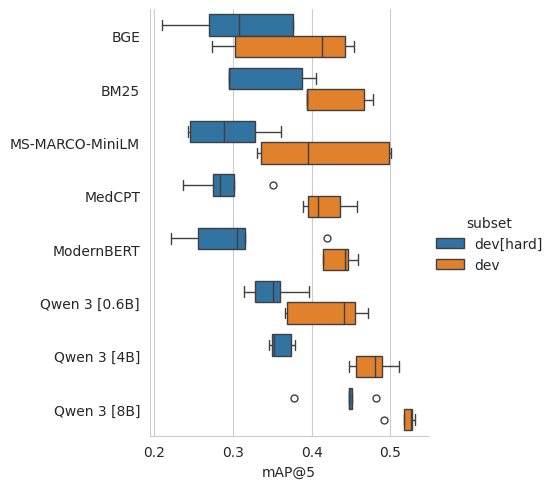

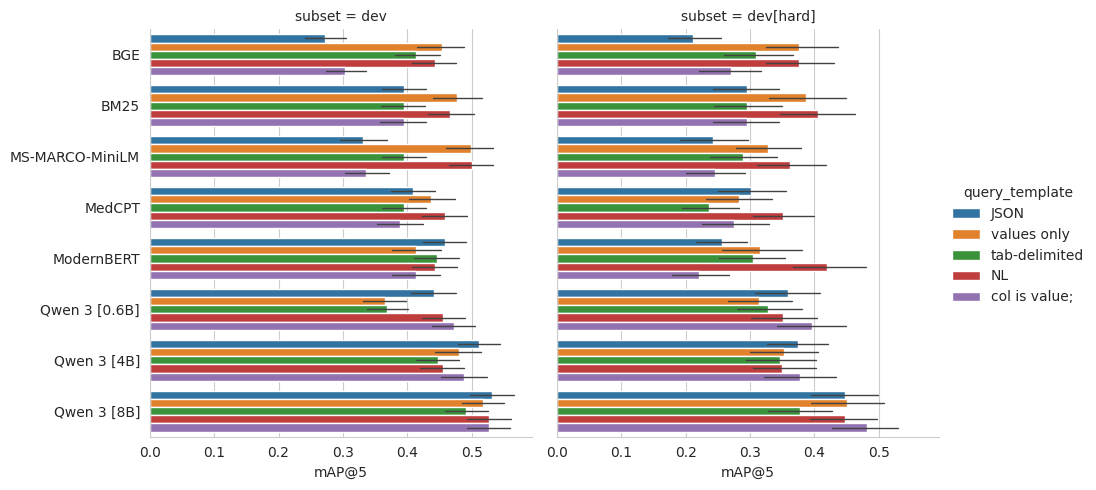

In [ ]:
# mAP@5
from utils.fig import add_bar_labels

k = 5
fig_df = both_df[ID_COLUMNS + ['subset']].merge(map_df)
qt_df = fig_df[(fig_df.k == k) & (fig_df['fine-tuned'] == 'no') & (~fig_df.model.isin({'head', 'BioMedBERT'}))].copy()
# do not bother plotting anything with only q query template tested
keep_df = qt_df.groupby(['model']).agg({'filepath.query_template': 'nunique'}).reset_index()
keep_df = keep_df[keep_df['filepath.query_template'] > 1]
qt_df = qt_df.merge(keep_df[['model']].drop_duplicates())
qt_df['mAP'] = qt_df['ap']

# drop any models where their max average mAP  is lower than the min average mAP of the bm25 index
means_df = qt_df.groupby(['query_template','filepath.query_template', 'model', 'subset']).agg({'mAP': 'mean'}).reset_index()
bm25_min = means_df[means_df.model == 'BM25']['mAP'].min()
means_df = means_df[means_df['mAP'] > bm25_min]
qt_df = qt_df.merge(means_df[['model']].drop_duplicates())


fig_df = qt_df.copy()
fig_df = fig_df.groupby(['query_template','filepath.query_template', 'model', 'subset']).agg({'mAP': 'mean'}).reset_index().sort_values(['mAP'])

bar_kws = dict(err_kws={'linewidth': 1}, estimator='mean', errorbar=('ci', 95), n_boot=1000)
fig = sns.catplot(fig_df.sort_values(['model']), x='mAP', y='model', kind='box',  hue='subset')
fig.set(xlabel=f'mAP@{k}', ylabel='')

#### also plot by individual template

fig_df = qt_df.copy()

bar_kws = dict(err_kws={'linewidth': 1}, estimator='mean', errorbar=('ci', 95), n_boot=1000)
fig = sns.catplot(fig_df.sort_values(['model', 'filepath.query_template']), x='mAP', hue='query_template', y='model',  kind='bar', palette='tab10', col='subset', **bar_kws)
fig.set(xlabel=f'mAP@{k}', ylabel='')

# add_bar_labels(fig, fmt=lambda x: round(x, 2), padding=5)
